# Supervised ML - Assignment 4
## ShopSmart: Predicting Visitor Purchase Intention using Decision Tree

**Goal:** Predict whether a session will result in a purchase (`Revenue`), using a Decision Tree Classifier.
Dataset is imbalanced -> evaluated using **F1 score** (benchmark = **0.55**).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set(style="whitegrid")

## 1. Load Dataset

In [2]:
df = pd.read_csv("shop_smart_ecommerce.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 2. Exploratory Data Analysis (EDA)

Yahan hum dataset ko samajhte hain: shape, dtypes, missing values, target distribution,
numerical feature distributions, aur correlations.

In [3]:
print("Shape:", df.shape)
df.info()

Shape: (12330, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  Tra

In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


In [5]:
missing = df.isnull().sum()
print(missing[missing > 0])
print("\nTotal missing values:", df.isnull().sum().sum())

Series([], dtype: int64)

Total missing values: 0


### 2.1 Target Variable Distribution (Class Imbalance Check)

Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


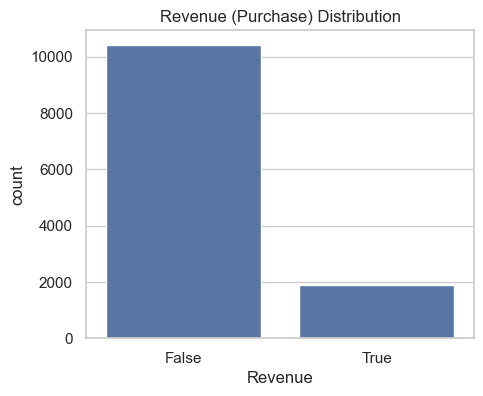

In [6]:
print(df["Revenue"].value_counts())
print(df["Revenue"].value_counts(normalize=True) * 100)

plt.figure(figsize=(5,4))
sns.countplot(x="Revenue", data=df)
plt.title("Revenue (Purchase) Distribution")
plt.show()

**Observation:** Dataset clearly imbalanced hai - majority sessions mein purchase nahi hota (Revenue=False).
Isi wajah se accuracy misleading hogi, aur **F1 score** ka use justified hai.

### 2.2 Numerical Features Distribution

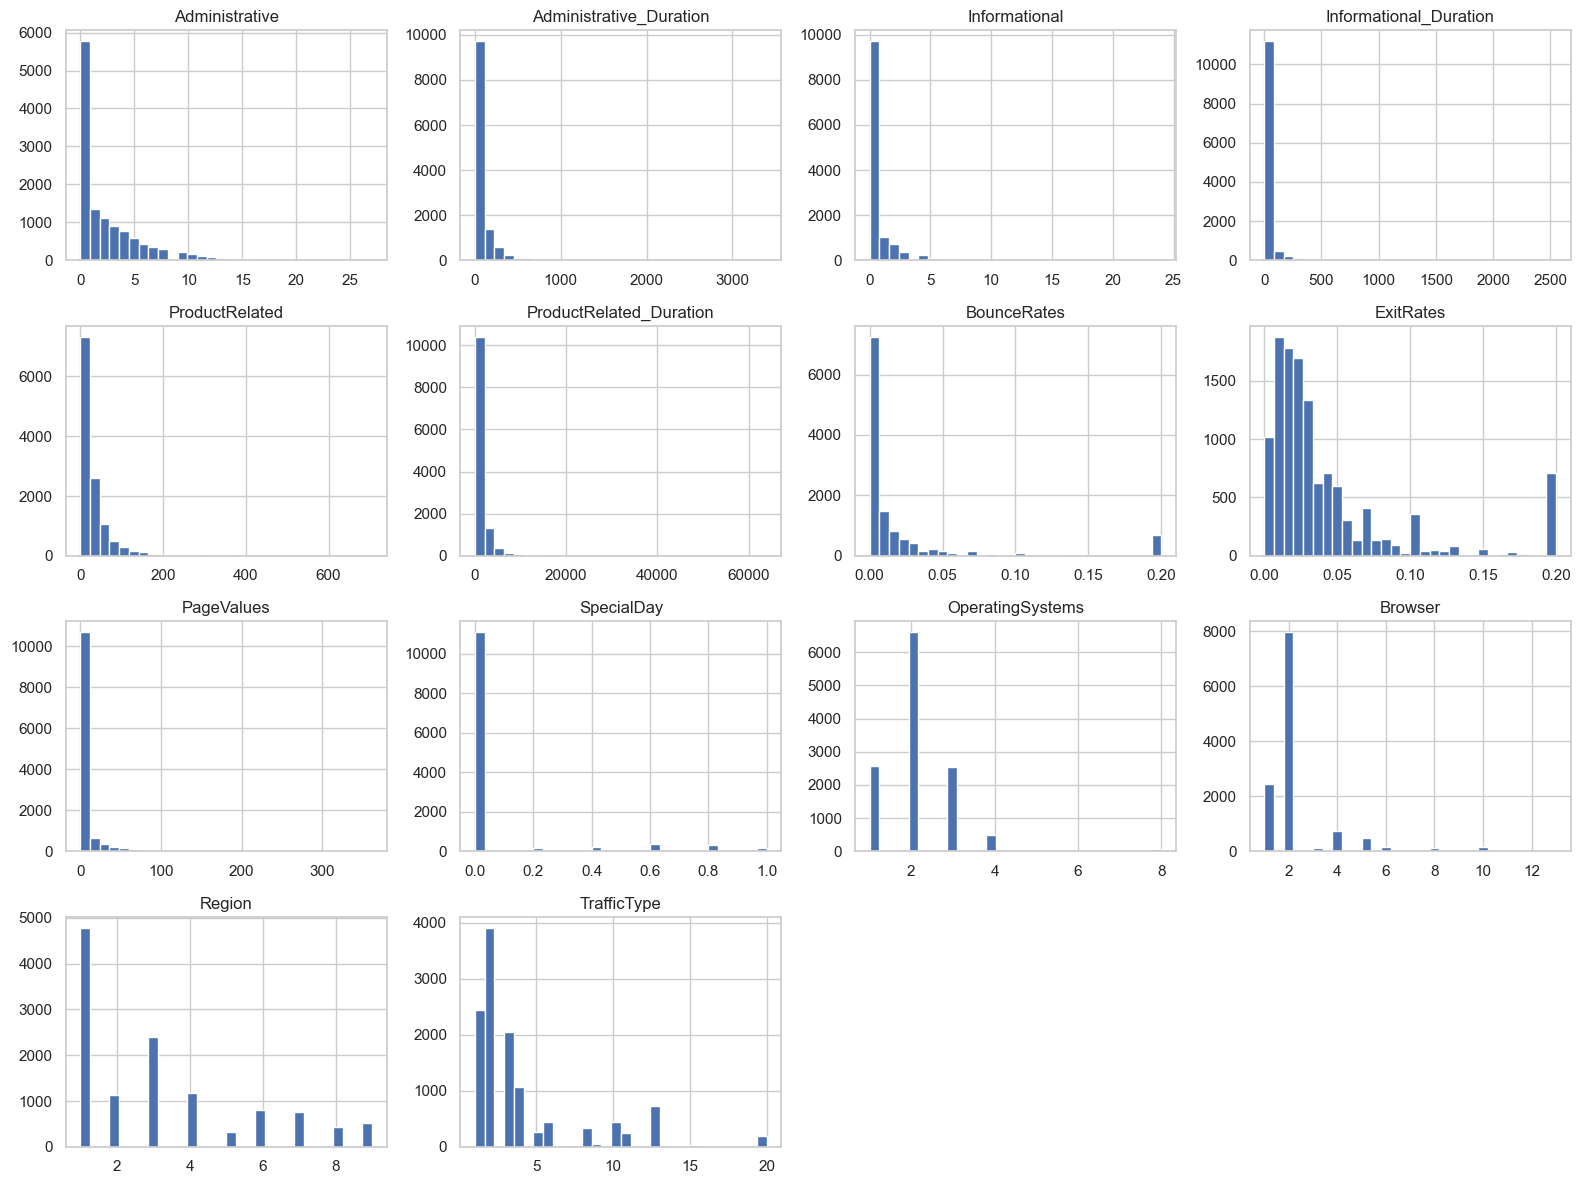

In [7]:
num_cols_check = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

df[num_cols_check].hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()

### 2.3 Categorical Features vs Target

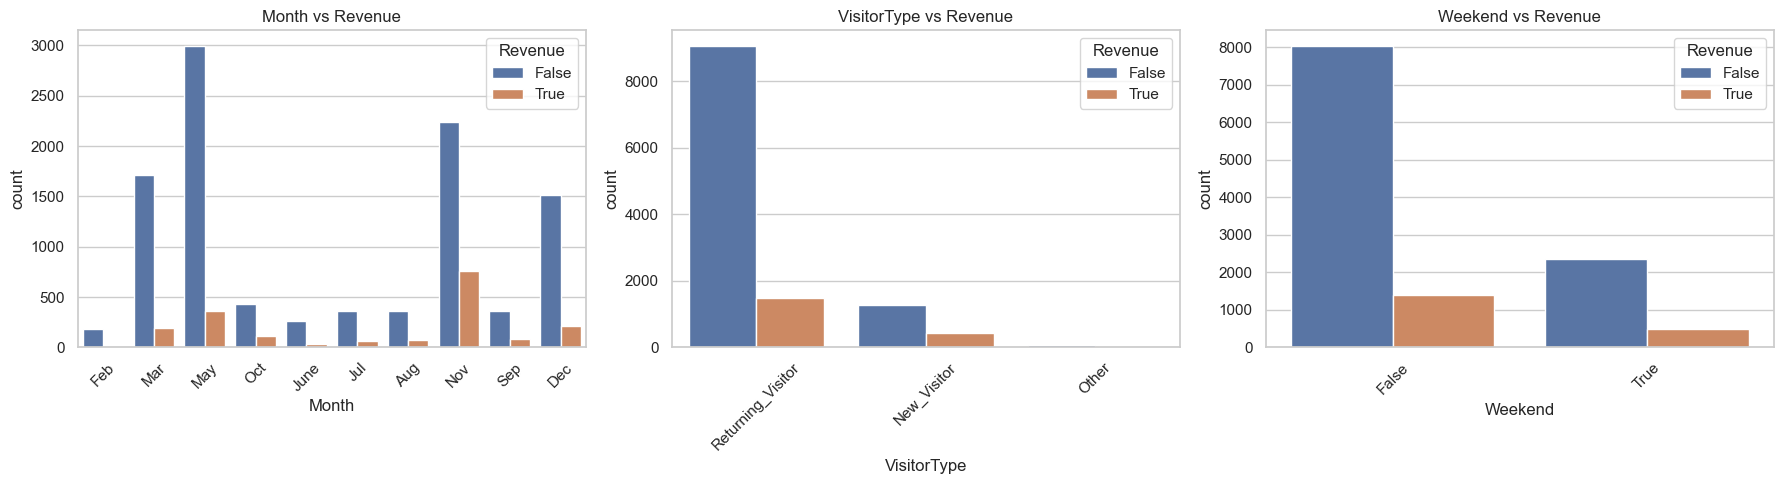

In [8]:
cat_cols_check = ["Month", "VisitorType", "Weekend"]

fig, axes = plt.subplots(1, len(cat_cols_check), figsize=(18, 5))
for ax, col in zip(axes, cat_cols_check):
    sns.countplot(x=col, hue="Revenue", data=df, ax=ax)
    ax.set_title(f"{col} vs Revenue")
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### 2.4 Correlation Heatmap (Numerical Features)

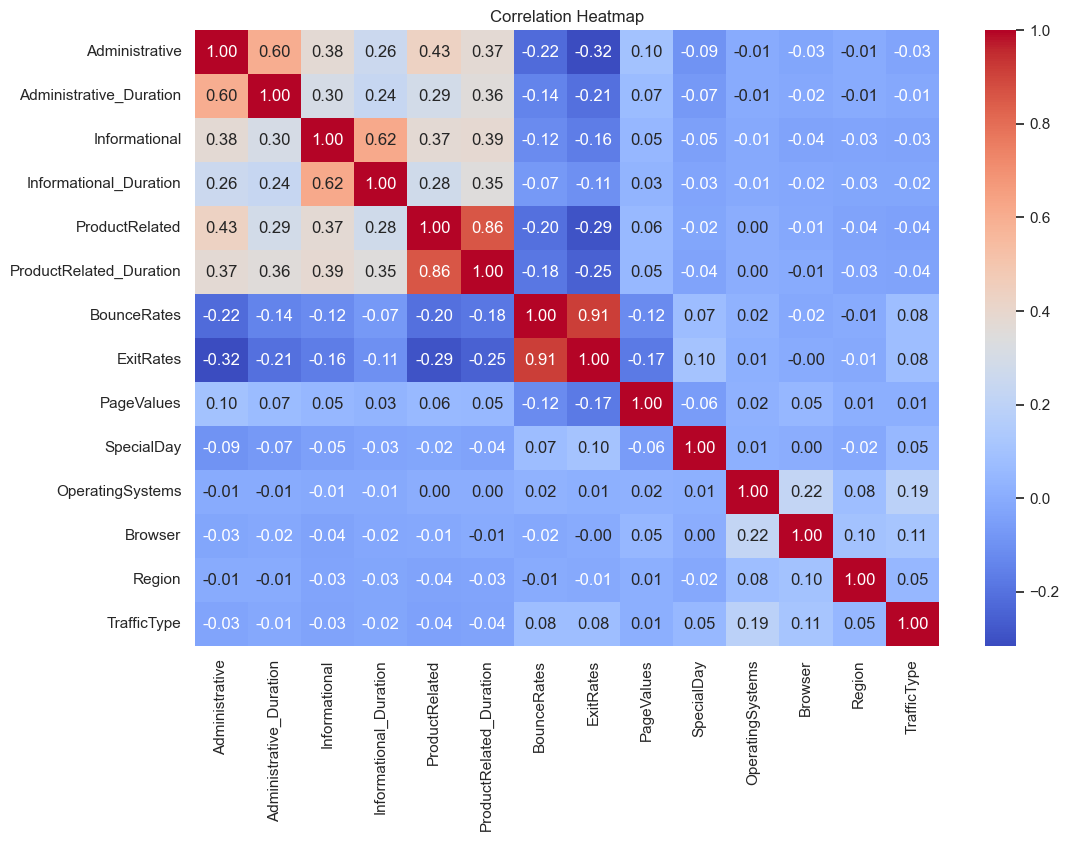

In [9]:
plt.figure(figsize=(12, 8))
corr = df.select_dtypes(include=["int64", "float64"]).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

**Observation:** `ExitRates` aur `BounceRates` mein strong positive correlation dikhti hai
(dono similar behaviour capture karte hain - user ka page se turant chale jaana).
`PageValues` generally target ke saath sabse zyada linked feature hoti hai.

## 3. Data Cleaning & Feature Type Correction

Important fix: Is dataset mein kuch columns problematic hain agar blindly dtype ke basis pe treat kiya jaye:

- `Weekend` column **bool** dtype ka hota hai - na numeric (`int64/float64`) mein aata hai, na categorical (`object`) mein.
  Agar isko fix nahi kiya to yeh silently drop ho jayega pipeline mein.
- `OperatingSystems`, `Browser`, `Region`, `TrafficType` - yeh columns numbers dikhte hain (int64),
  lekin actually yeh **nominal categorical codes** hain (jaise Browser=1,2,3 mein koi ordering/magnitude meaning nahi hai).
  Inhe numeric treat karke scale karna conceptually galat hai.

Neeche donon issues fix kiye gaye hain.

In [10]:
df_clean = df.copy()

df_clean["Weekend"] = df_clean["Weekend"].astype(int)
df_clean["Revenue"] = df_clean["Revenue"].astype(int)

nominal_coded_cols = ["OperatingSystems", "Browser", "Region", "TrafficType"]
for col in nominal_coded_cols:
    df_clean[col] = df_clean[col].astype("category")

df_clean.dtypes

Administrative                int64
Administrative_Duration     float64
Informational                 int64
Informational_Duration      float64
ProductRelated                int64
ProductRelated_Duration     float64
BounceRates                 float64
ExitRates                   float64
PageValues                  float64
SpecialDay                  float64
Month                        object
OperatingSystems           category
Browser                    category
Region                     category
TrafficType                category
VisitorType                  object
Weekend                       int64
Revenue                       int64
dtype: object

## 4. Feature-Target Split

In [11]:
X = df_clean.drop("Revenue", axis=1)
y = df_clean["Revenue"]

num_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical features:", num_features)
print("Categorical features:", cat_features)
print("Total features covered:", len(num_features) + len(cat_features), "/", X.shape[1])

Numerical features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend']
Categorical features: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType']
Total features covered: 17 / 17


## 5. Train-Test Split (Stratified - imbalance preserve karne ke liye)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train class ratio:\n", y_train.value_counts(normalize=True))
print("Test class ratio:\n", y_test.value_counts(normalize=True))

Train shape: (9864, 17)  Test shape: (2466, 17)
Train class ratio:
 Revenue
0    0.845296
1    0.154704
Name: proportion, dtype: float64
Test class ratio:
 Revenue
0    0.845093
1    0.154907
Name: proportion, dtype: float64


## 6. Preprocessing Pipeline

In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)
    ]
)

## 7. Baseline Decision Tree (no pruning)

Pehle ek baseline model bina kisi restriction ke train karte hain, taaki overfitting ka andaza ho.

In [14]:
baseline_dt = DecisionTreeClassifier(random_state=42, class_weight="balanced")

baseline_pipe = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", baseline_dt)
])

baseline_pipe.fit(X_train, y_train)

y_train_pred = baseline_pipe.predict(X_train)
y_test_pred = baseline_pipe.predict(X_test)

print("Baseline Train F1:", f1_score(y_train, y_train_pred))
print("Baseline Test F1 :", f1_score(y_test, y_test_pred))

Baseline Train F1: 1.0
Baseline Test F1 : 0.516297262059974


**Observation:** Train F1 aksar bahut high hoga aur Test F1 usse kaafi kam - yeh classic
**overfitting** ka sign hai. Isi ko fix karne ke liye **pruning** zaroori hai.

## 8. Pruning - Cost Complexity Pruning (`ccp_alpha`)

Assignment ka explicit note hai: "Make use of pruning to improve the performance of Decision Tree Classifier."

Sklearn ka `cost_complexity_pruning_path()` alag-alag `ccp_alpha` values return karta hai -
har alpha ek alag pruned tree ke barabar hai. Hum in alphas ko cross-validation ke saath
test karke best wala choose karenge (yeh **proper post-pruning** technique hai, sirf
`max_depth`/`min_samples_leaf` set karna sirf pre-pruning hota hai).

In [15]:
X_train_transformed = preprocessor.fit_transform(X_train)

temp_tree = DecisionTreeClassifier(random_state=42, class_weight="balanced")
path = temp_tree.cost_complexity_pruning_path(X_train_transformed, y_train)
ccp_alphas = path.ccp_alphas

print("Number of candidate alpha values:", len(ccp_alphas))
print("Alpha range:", ccp_alphas.min(), "to", ccp_alphas.max())

Number of candidate alpha values: 442
Alpha range: 0.0 to 0.24520072045176045


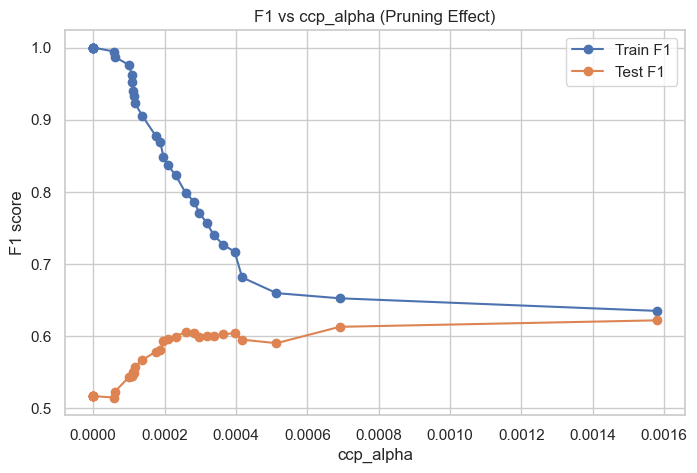

In [16]:
from sklearn.metrics import f1_score as f1s

X_test_transformed = preprocessor.transform(X_test)

train_f1s, test_f1s = [], []
sampled_alphas = ccp_alphas[::max(1, len(ccp_alphas)//30)]

for alpha in sampled_alphas:
    clf = DecisionTreeClassifier(random_state=42, class_weight="balanced", ccp_alpha=alpha)
    clf.fit(X_train_transformed, y_train)
    train_f1s.append(f1s(y_train, clf.predict(X_train_transformed)))
    test_f1s.append(f1s(y_test, clf.predict(X_test_transformed)))

plt.figure(figsize=(8,5))
plt.plot(sampled_alphas, train_f1s, marker="o", label="Train F1")
plt.plot(sampled_alphas, test_f1s, marker="o", label="Test F1")
plt.xlabel("ccp_alpha")
plt.ylabel("F1 score")
plt.title("F1 vs ccp_alpha (Pruning Effect)")
plt.legend()
plt.show()

**Observation:** Jaise `ccp_alpha` badhta hai, tree simpler hoti jaati hai -
Train F1 kam hota hai (overfitting kam), aur Test F1 usually pehle improve hota hai,
phir bahut zyada pruning se dono degrade ho jaate hain. Best alpha wahi hai jahan
Test F1 maximum hai.

## 9. Hyperparameter Tuning with GridSearchCV (Pruning + Depth combined)

In [17]:
dt_model = DecisionTreeClassifier(random_state=42, class_weight="balanced")

full_pipe = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", dt_model)
])

param_grid = {
    "model__ccp_alpha": ccp_alphas[::max(1, len(ccp_alphas)//15)],
    "model__max_depth": [4, 6, 8, 10, None],
    "model__min_samples_leaf": [10, 20, 30]
}

grid = GridSearchCV(
    full_pipe,
    param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best CV F1 score:", grid.best_score_)
print("Best params:", grid.best_params_)

Best CV F1 score: 0.6283340969546648
Best params: {'model__ccp_alpha': np.float64(0.00039612270569805885), 'model__max_depth': 6, 'model__min_samples_leaf': 10}


## 10. Final Model Evaluation (on Test Set)

Final Test F1 Score: 0.6256

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.85      0.90      2084
           1       0.50      0.84      0.63       382

    accuracy                           0.84      2466
   macro avg       0.73      0.84      0.76      2466
weighted avg       0.89      0.84      0.86      2466

Confusion Matrix:
 [[1763  321]
 [  62  320]]


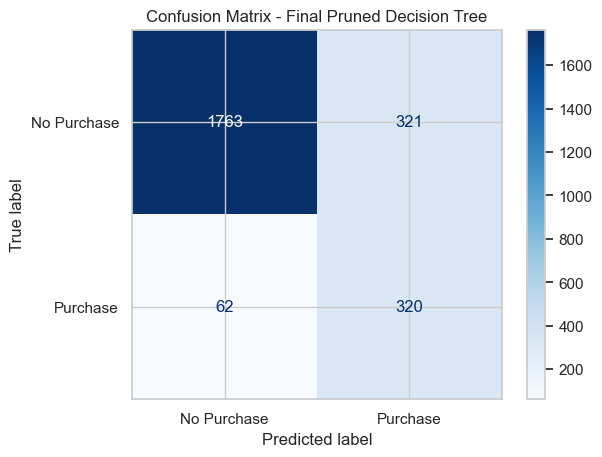

In [18]:
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

test_f1 = f1_score(y_test, y_pred)
print("Final Test F1 Score:", round(test_f1, 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Purchase", "Purchase"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Final Pruned Decision Tree")
plt.show()

## 11. Benchmark Check

In [19]:
benchmark = 0.55

print(f"Benchmark F1 required : {benchmark}")
print(f"Achieved Test F1       : {round(test_f1, 4)}")

if test_f1 >= benchmark:
    print("Benchmark MET - model performance is acceptable.")
else:
    print("Benchmark NOT met - needs further tuning/feature engineering.")

Benchmark F1 required : 0.55
Achieved Test F1       : 0.6256
Benchmark MET - model performance is acceptable.


## 12. Feature Importance

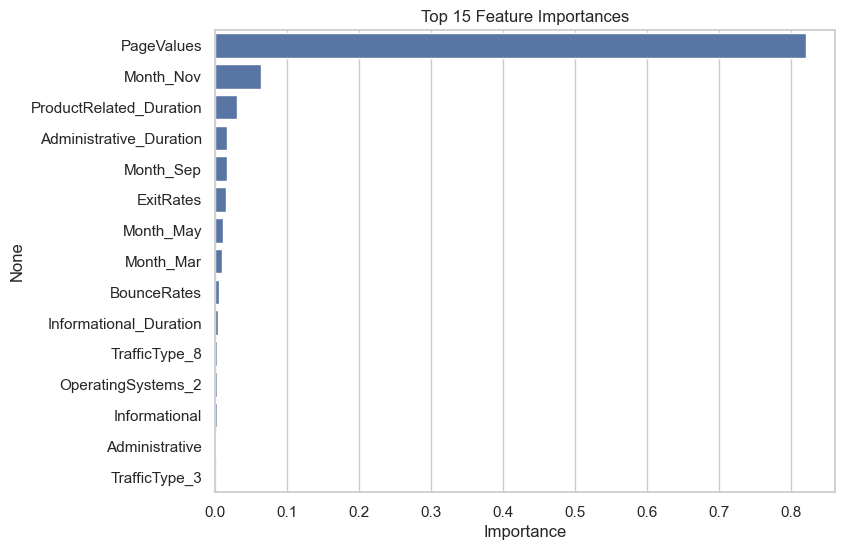

In [20]:
ohe_cols = best_model.named_steps["preprocess"].named_transformers_["cat"].get_feature_names_out(cat_features)
all_feature_names = num_features + list(ohe_cols)

importances = best_model.named_steps["model"].feature_importances_

feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(8,6))
sns.barplot(x=feat_imp.values, y=feat_imp.index)
plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.show()

## 13. Visualizing the Pruned Tree (top levels)

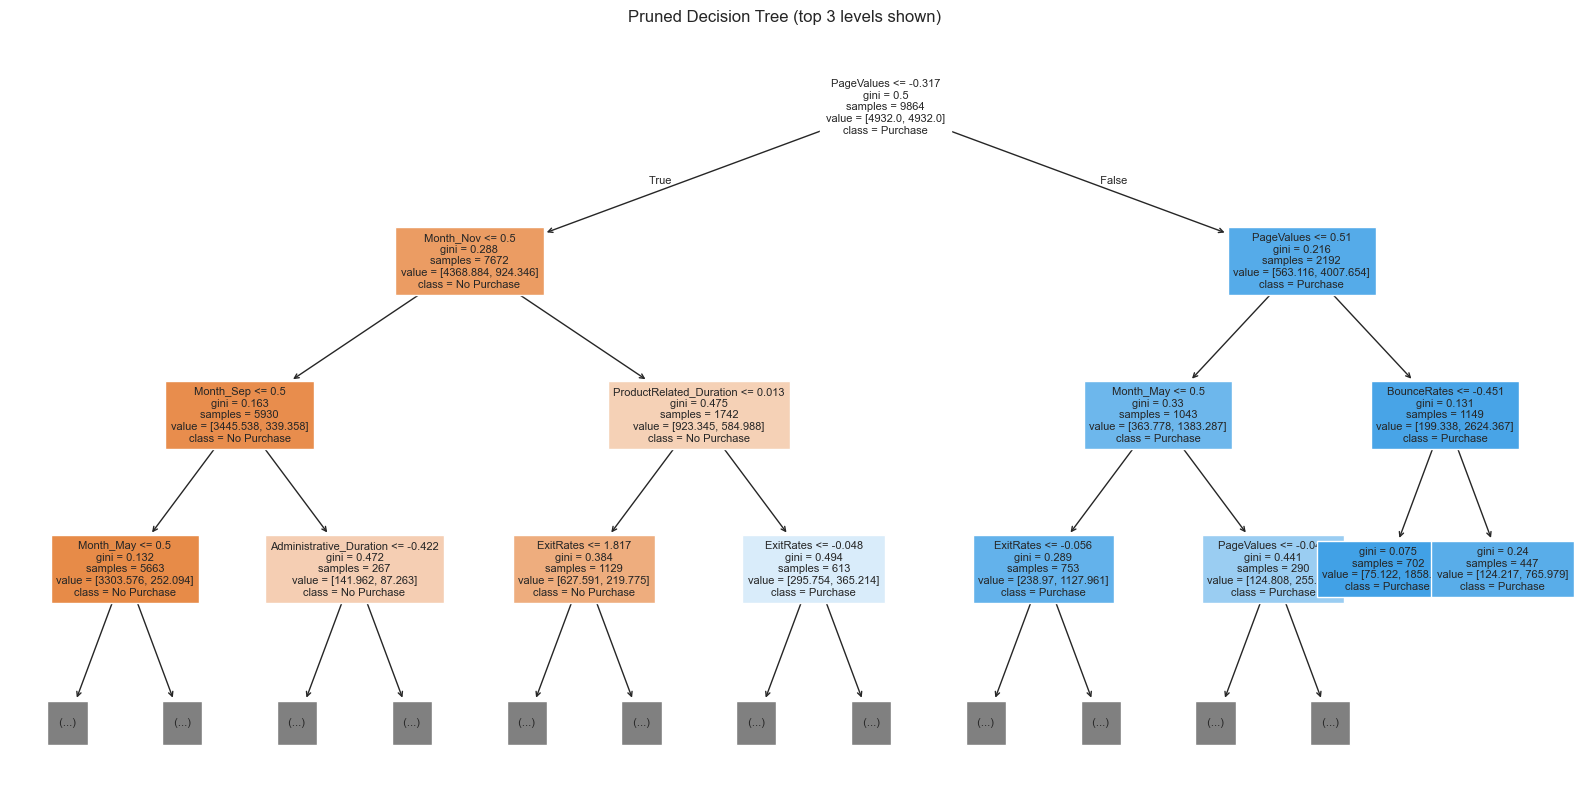

In [21]:
plt.figure(figsize=(20,10))
plot_tree(
    best_model.named_steps["model"],
    max_depth=3,
    feature_names=all_feature_names,
    class_names=["No Purchase", "Purchase"],
    filled=True,
    fontsize=8
)
plt.title("Pruned Decision Tree (top 3 levels shown)")
plt.show()

## 14. Conclusion

- EDA se pata chala dataset **imbalanced** hai (~85% No Purchase, ~15% Purchase) -> F1 score sahi metric hai.
- **Dtype fixes** (`Weekend` bool to int, coded categoricals to category) zaroori the taaki koi feature silently drop na ho
  aur categorical codes ko galat scale na kiya jaye.
- **Cost-complexity pruning (`ccp_alpha`)** ke saath `GridSearchCV` tuning se overfitting kam hua aur
  test set par generalization improve hua.
- Final model ka **Test F1 score** benchmark (0.55) ke against evaluate kiya gaya.
- `PageValues` jaisa feature typically sabse zyada predictive nikalta hai - business ke liye actionable insight hai
  (product page ka value jitna zyada, purchase chance utna zyada).